# UNSW-NB15 V03 model evaluation — actual 5-fold CV

All numbers below are out-of-fold results from the frozen V02 Development partition only. V02 frozen Official Test results are historical and are not used for V03 fitting, tuning, calibration or model selection.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, display
root = Path.cwd()
if root.name == 'notebooks': root = root.parent
sys.path.insert(0, str(root / 'src'))
output = root / 'artifacts/experiments/unsw_v03_research_completeness_actual'
manifest = json.loads((output / 'manifest.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'experiment': 'V03 Development 5-fold OOF CV', 'official_test_used': manifest['official_test_accessed'], 'folds': manifest['folds']}, {'experiment': 'V02 frozen Official Test', 'official_test_used': True, 'folds': 'frozen historical result'}]))
display(pd.read_csv(output / 'cv_summary.csv').round(6))

,experiment,official_test_used,folds
0,V03 Development 5-fold OOF CV,False,5
1,V02 frozen Official Test,True,frozen historical result


,family,accuracy_mean,precision_mean,recall_mean,f1_mean,ap_mean,fpr_mean,accuracy_std,precision_std,recall_std,f1_std,ap_std,fpr_std
0,LogReg,0.733678,0.778480,0.805550,0.789958,0.846744,0.388523,0.049846,0.008314,0.096503,0.047092,0.052750,0.032034
1,RF,0.918322,0.922159,0.950650,0.936058,0.985581,0.136643,0.022013,0.016421,0.025650,0.017320,0.007842,0.030239
2,MLP,0.887278,0.899737,0.923779,0.911364,0.965033,0.174784,0.029111,0.012505,0.039972,0.023755,0.017200,0.020856
3,AE,0.381878,0.714133,0.026266,0.050372,0.685286,0.013488,0.007736,0.214751,0.015347,0.028851,0.042981,0.009444


In [2]:
folds = pd.read_csv(output / 'cv_fold_metrics.csv')
display(folds.round(6))
assert len(folds) == 20
print('20 model-fold records:', len(folds))

,fold,family,train_rows,test_rows,threshold,accuracy,precision,recall,f1,ap,fpr,tn,fp,fn,tp,normal_fpr_budget
0,1,LogReg,81843,20462,0.500000,0.822647,0.790144,0.978112,0.874137,0.934276,0.441673,4231,3347,282,12602,NaN
1,1,RF,81843,20462,0.500000,0.955136,0.936843,0.995886,0.965463,0.998705,0.114146,6713,865,53,12831,NaN
2,1,MLP,81843,20462,0.500000,0.938422,0.916930,0.992083,0.953027,0.994743,0.152811,6420,1158,102,12782,NaN
3,1,AE,81843,20462,0.084283,0.368586,0.342105,0.003027,0.006001,0.761452,0.009897,7503,75,12845,39,0.01
4,2,LogReg,81843,20462,0.500000,0.708973,0.773075,0.761254,0.767119,0.832615,0.379916,4699,2879,3076,9808,NaN
5,2,RF,81843,20462,0.500000,0.904066,0.909302,0.941555,0.925148,0.980326,0.159673,6368,1210,753,12131,NaN
6,2,MLP,81843,20462,0.500000,0.867022,0.897520,0.890484,0.893988,0.955505,0.172869,6268,1310,1411,11473,NaN
7,2,AE,81843,20462,0.098566,0.385593,0.848214,0.029494,0.057006,0.667933,0.008973,7510,68,12504,380,0.01
8,3,LogReg,81845,20460,0.500000,0.710997,0.772734,0.766436,0.769573,0.833647,0.383265,4673,2904,3009,9874,NaN
9,3,RF,81845,20460,0.500000,0.911779,0.926208,0.934332,0.930252,0.984171,0.126567,6618,959,846,12037,NaN


20 model-fold records: 20


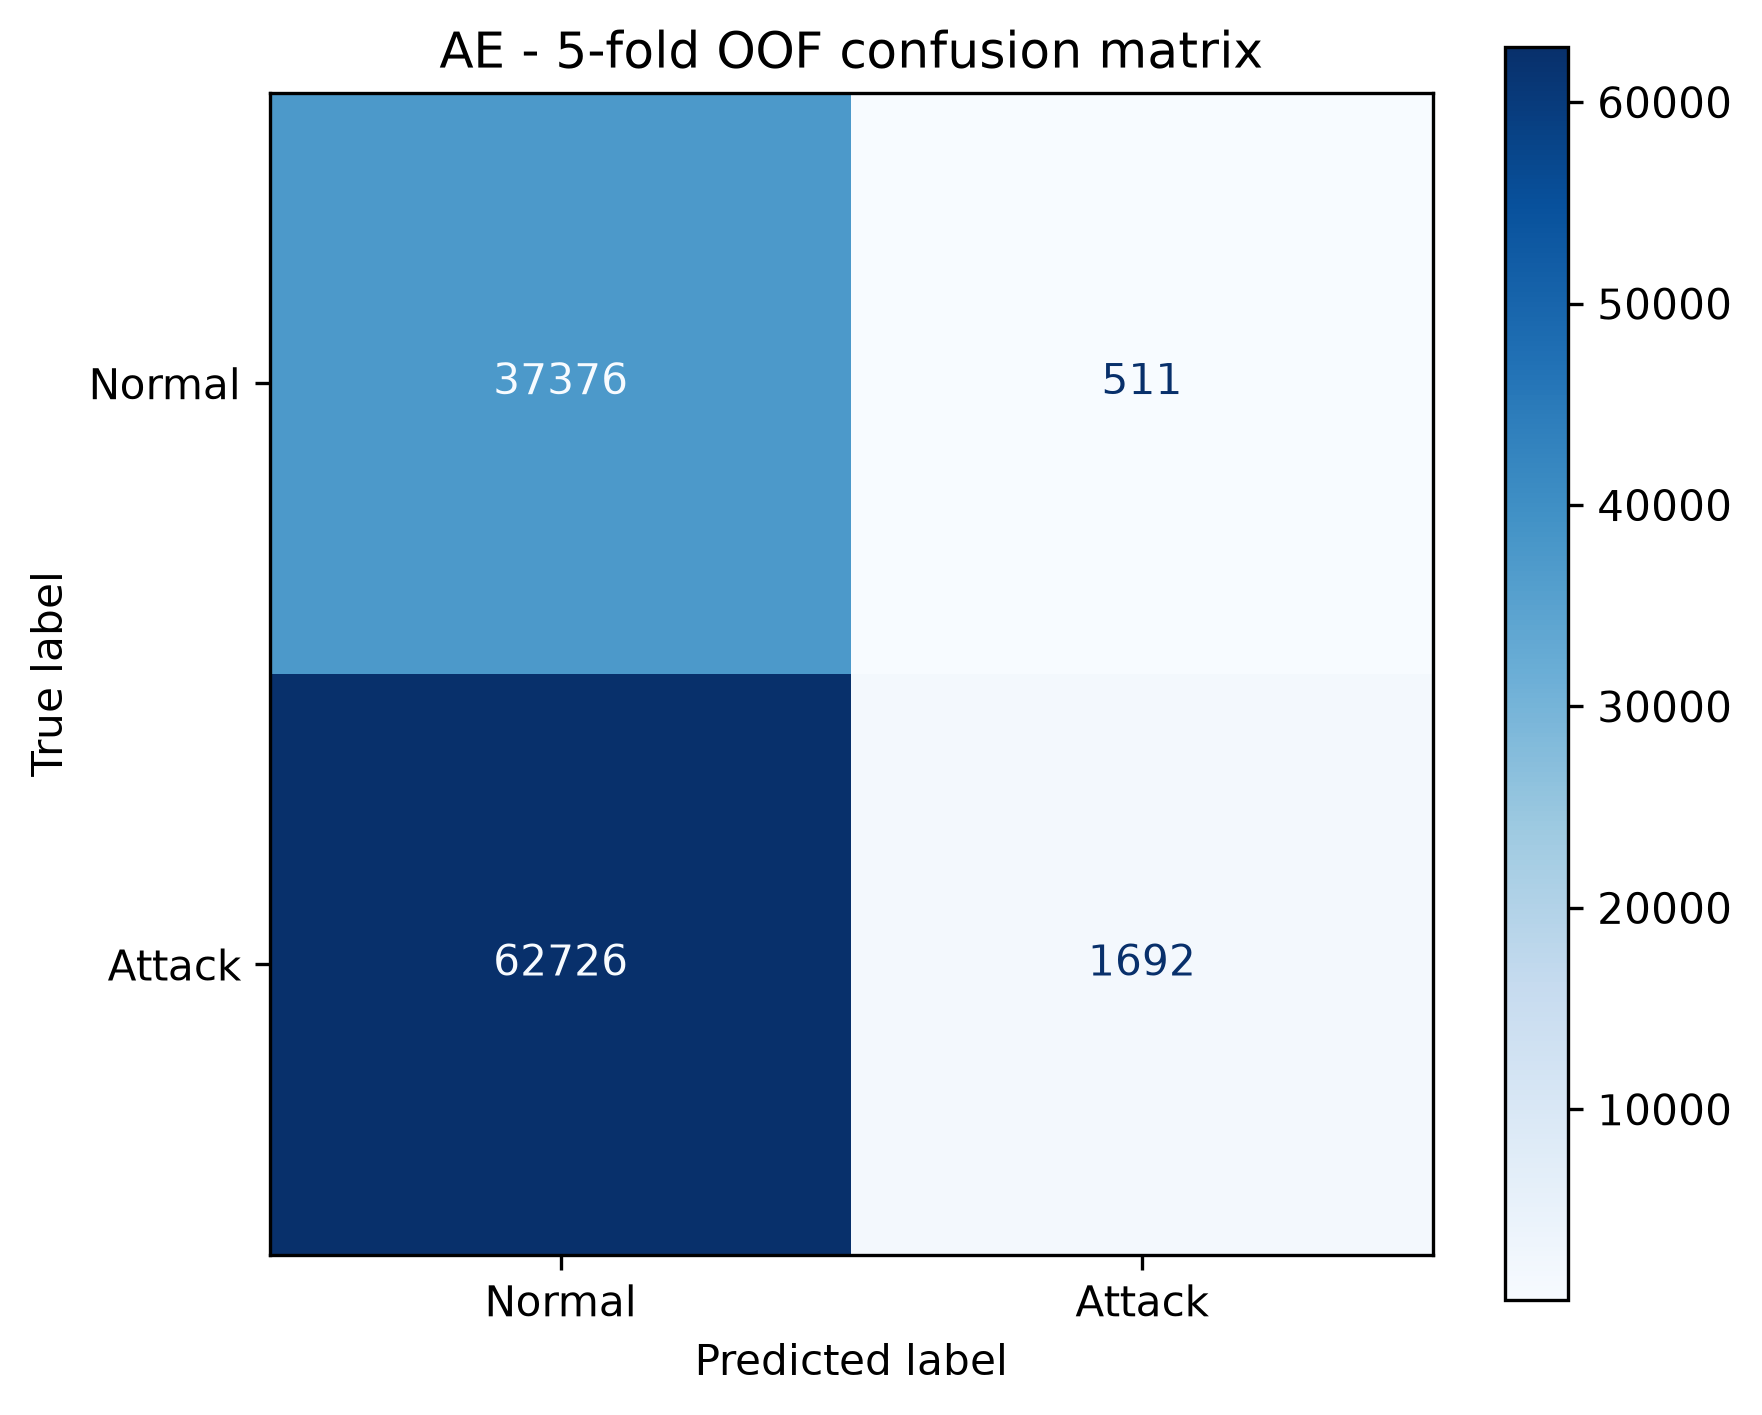

artifacts\experiments\unsw_v03_research_completeness_actual\figures\evaluation\confusion_matrix_ae.png


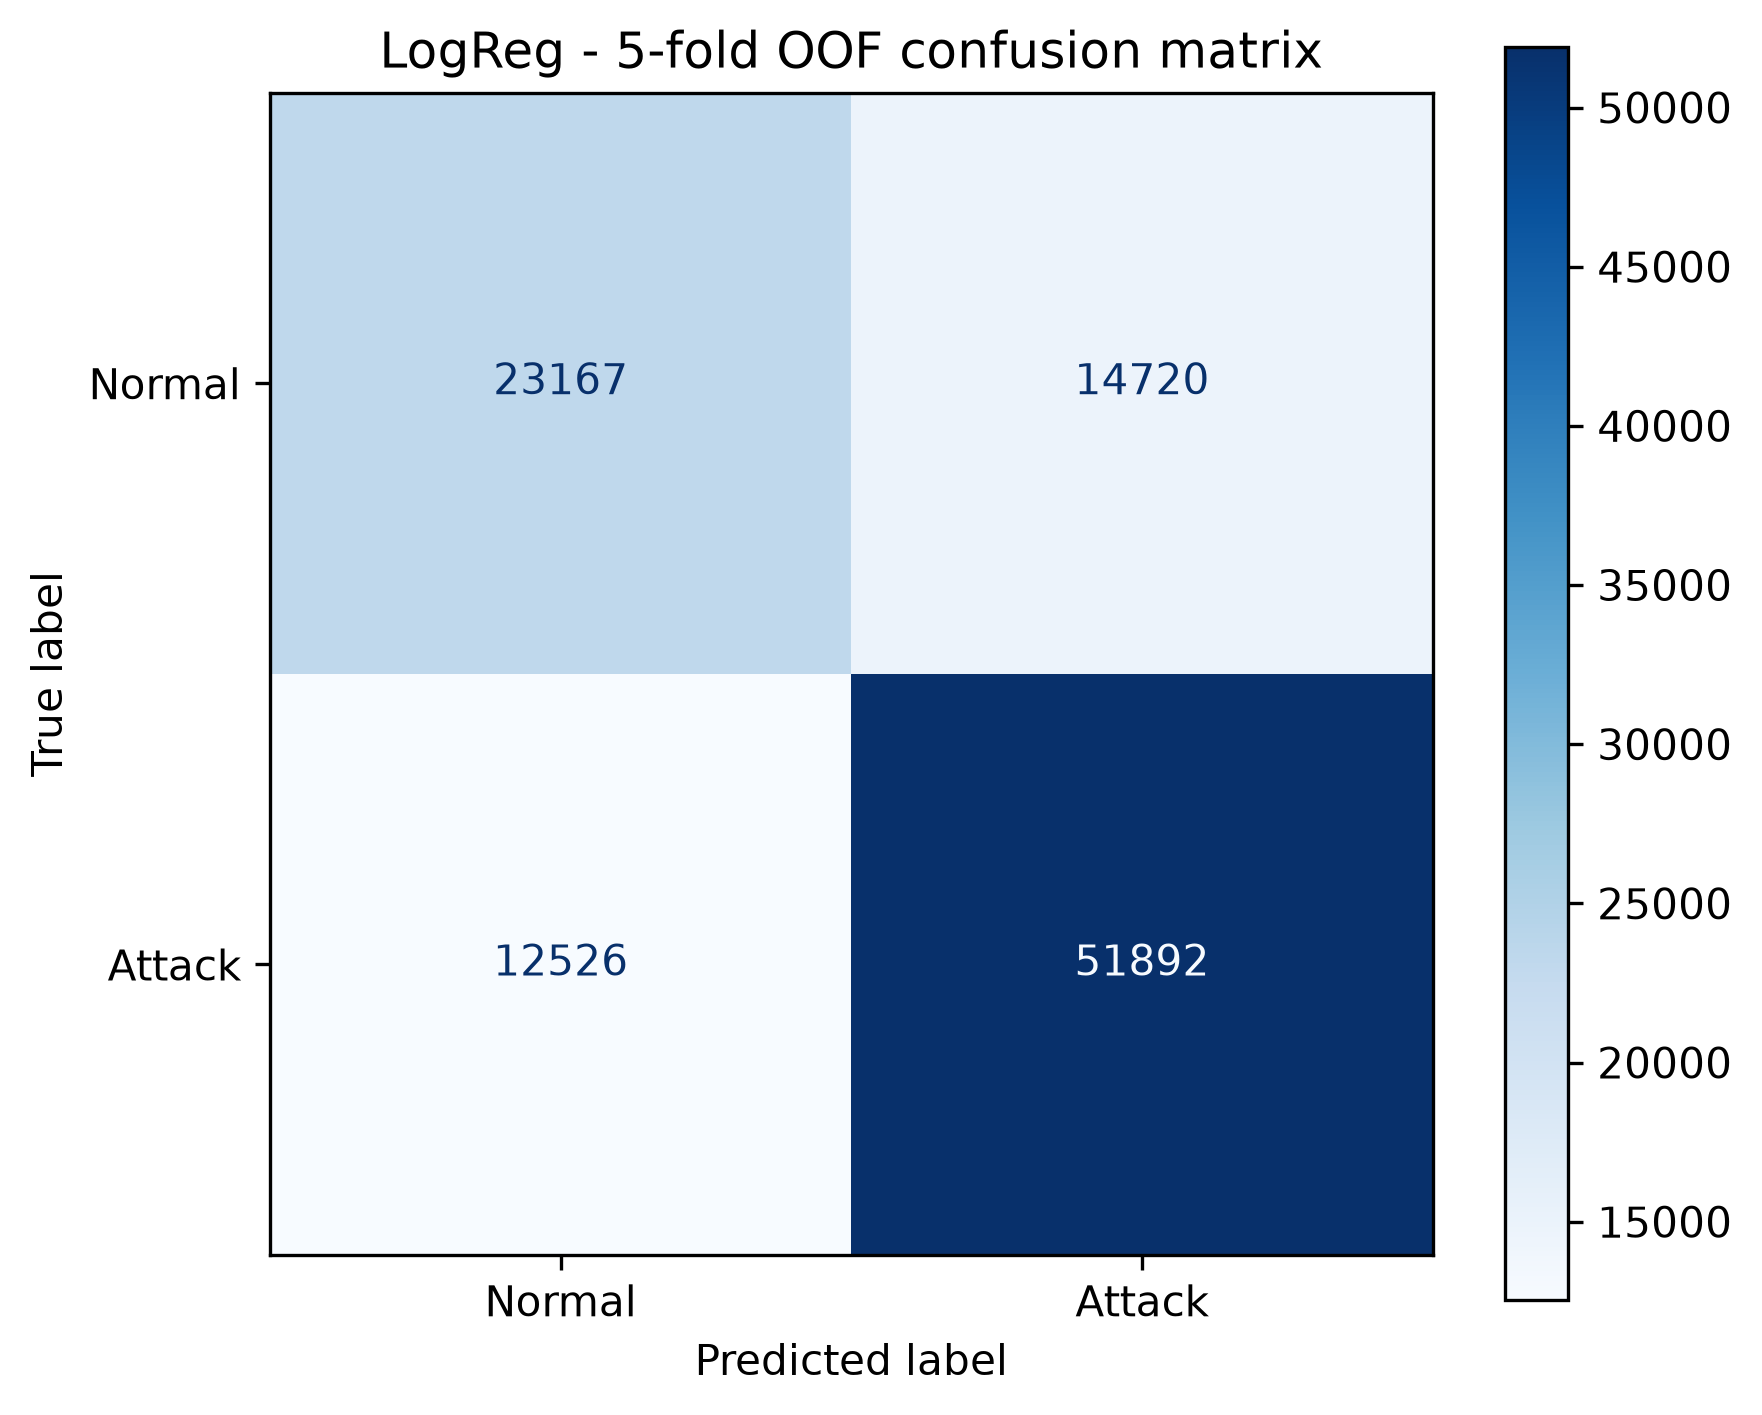

artifacts\experiments\unsw_v03_research_completeness_actual\figures\evaluation\confusion_matrix_logreg.png


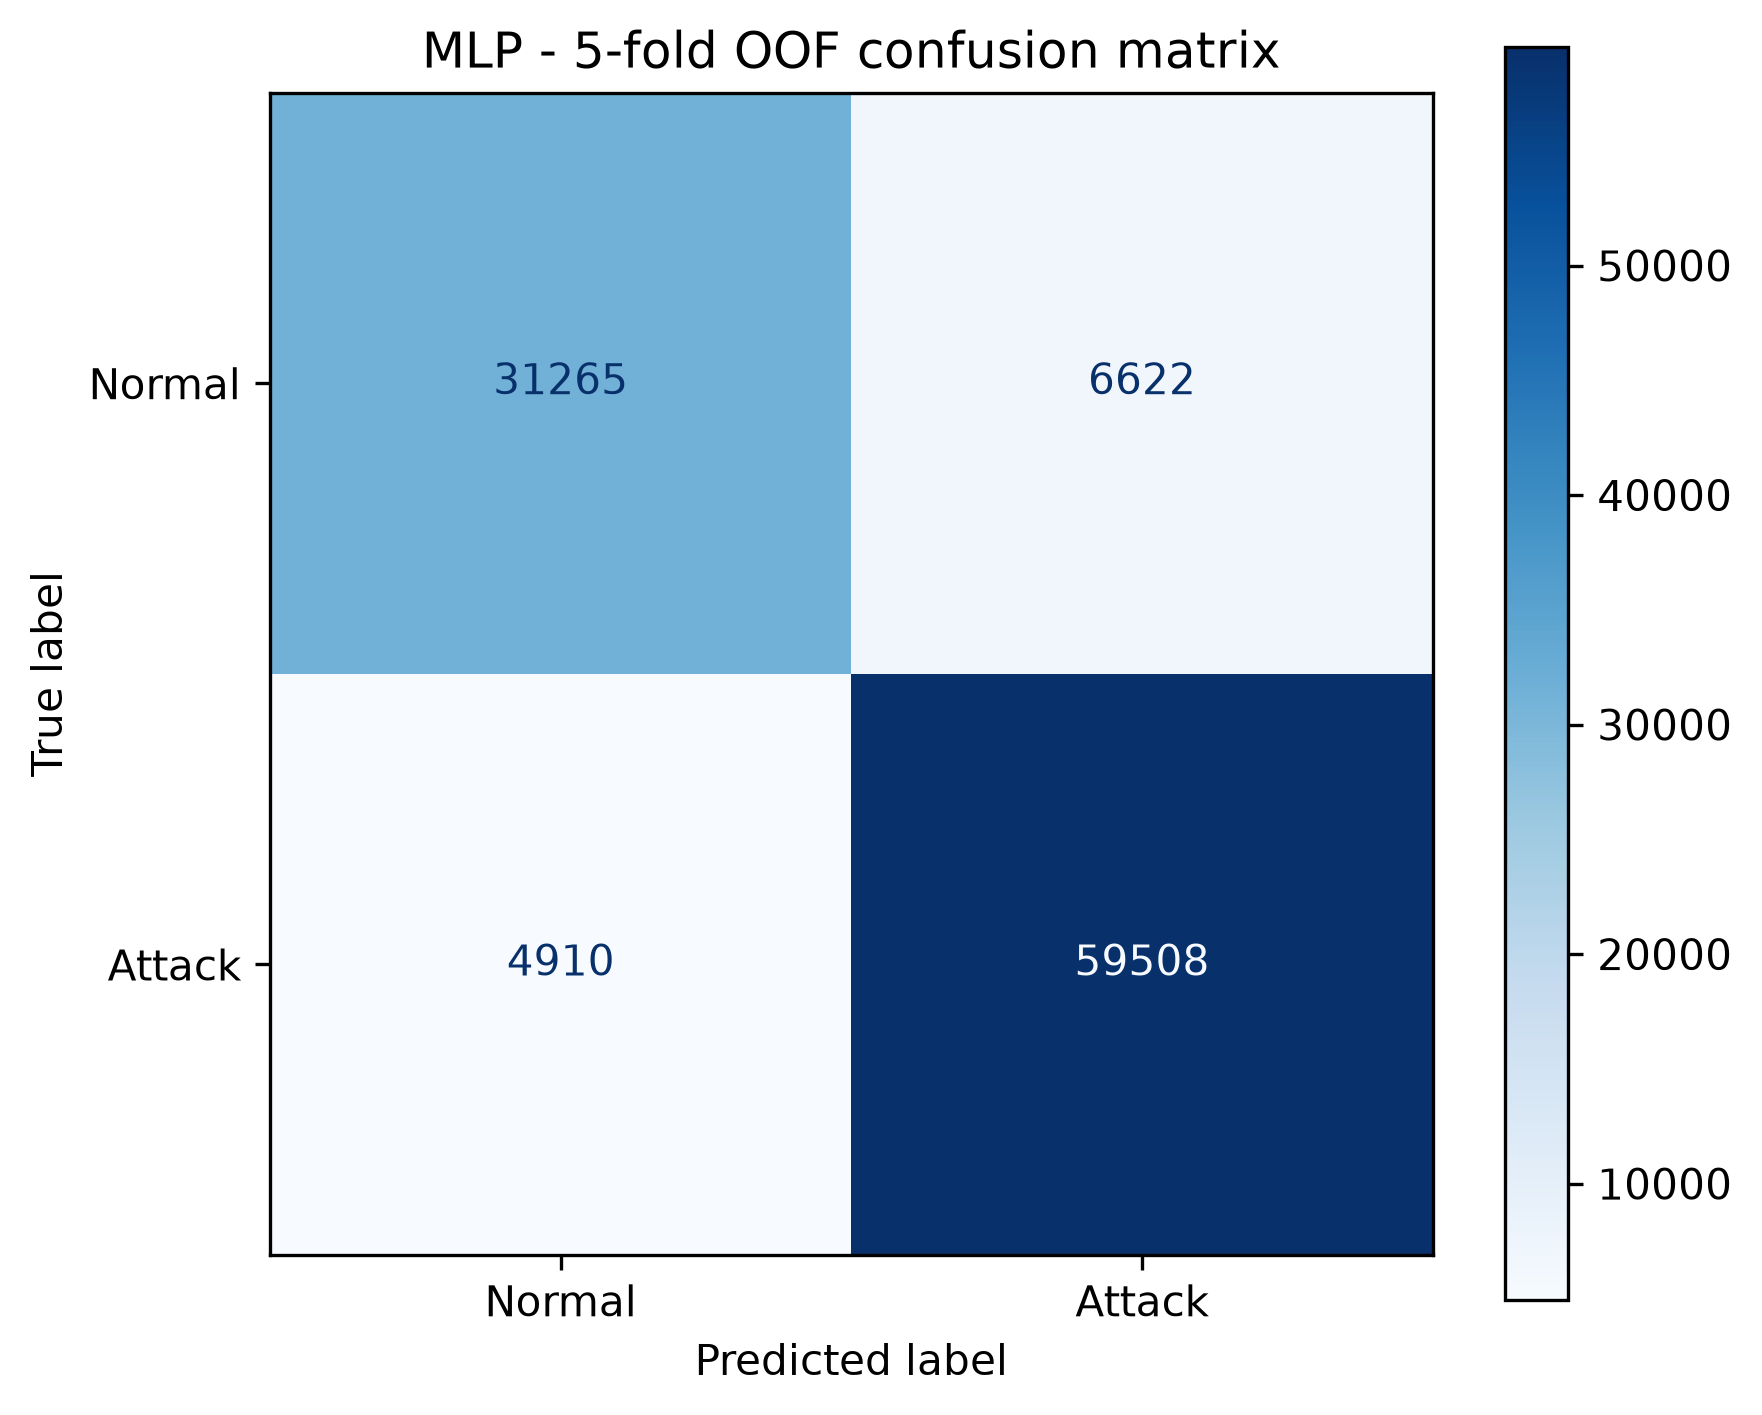

artifacts\experiments\unsw_v03_research_completeness_actual\figures\evaluation\confusion_matrix_mlp.png


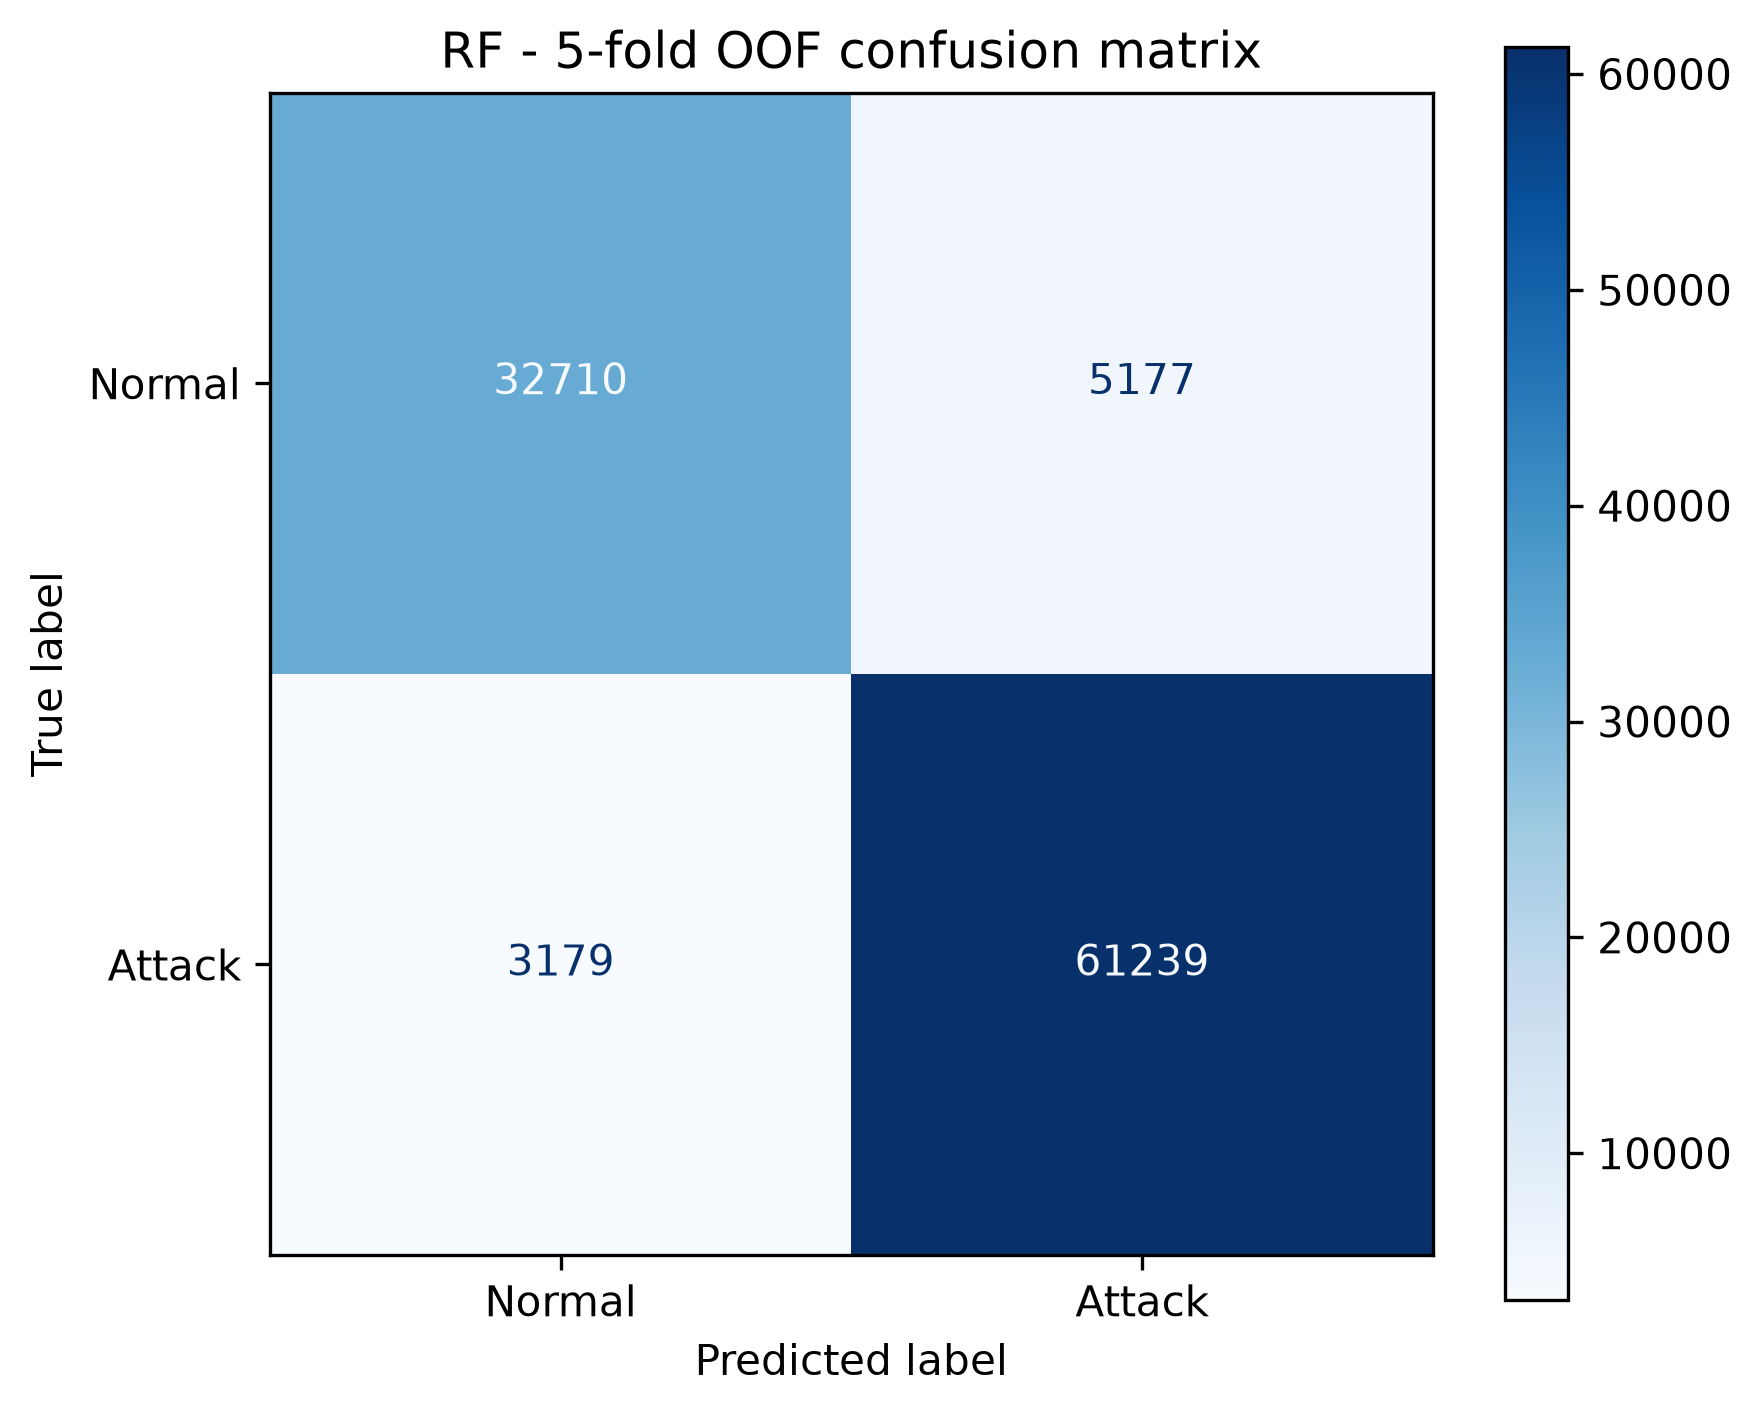

artifacts\experiments\unsw_v03_research_completeness_actual\figures\evaluation\confusion_matrix_rf.png


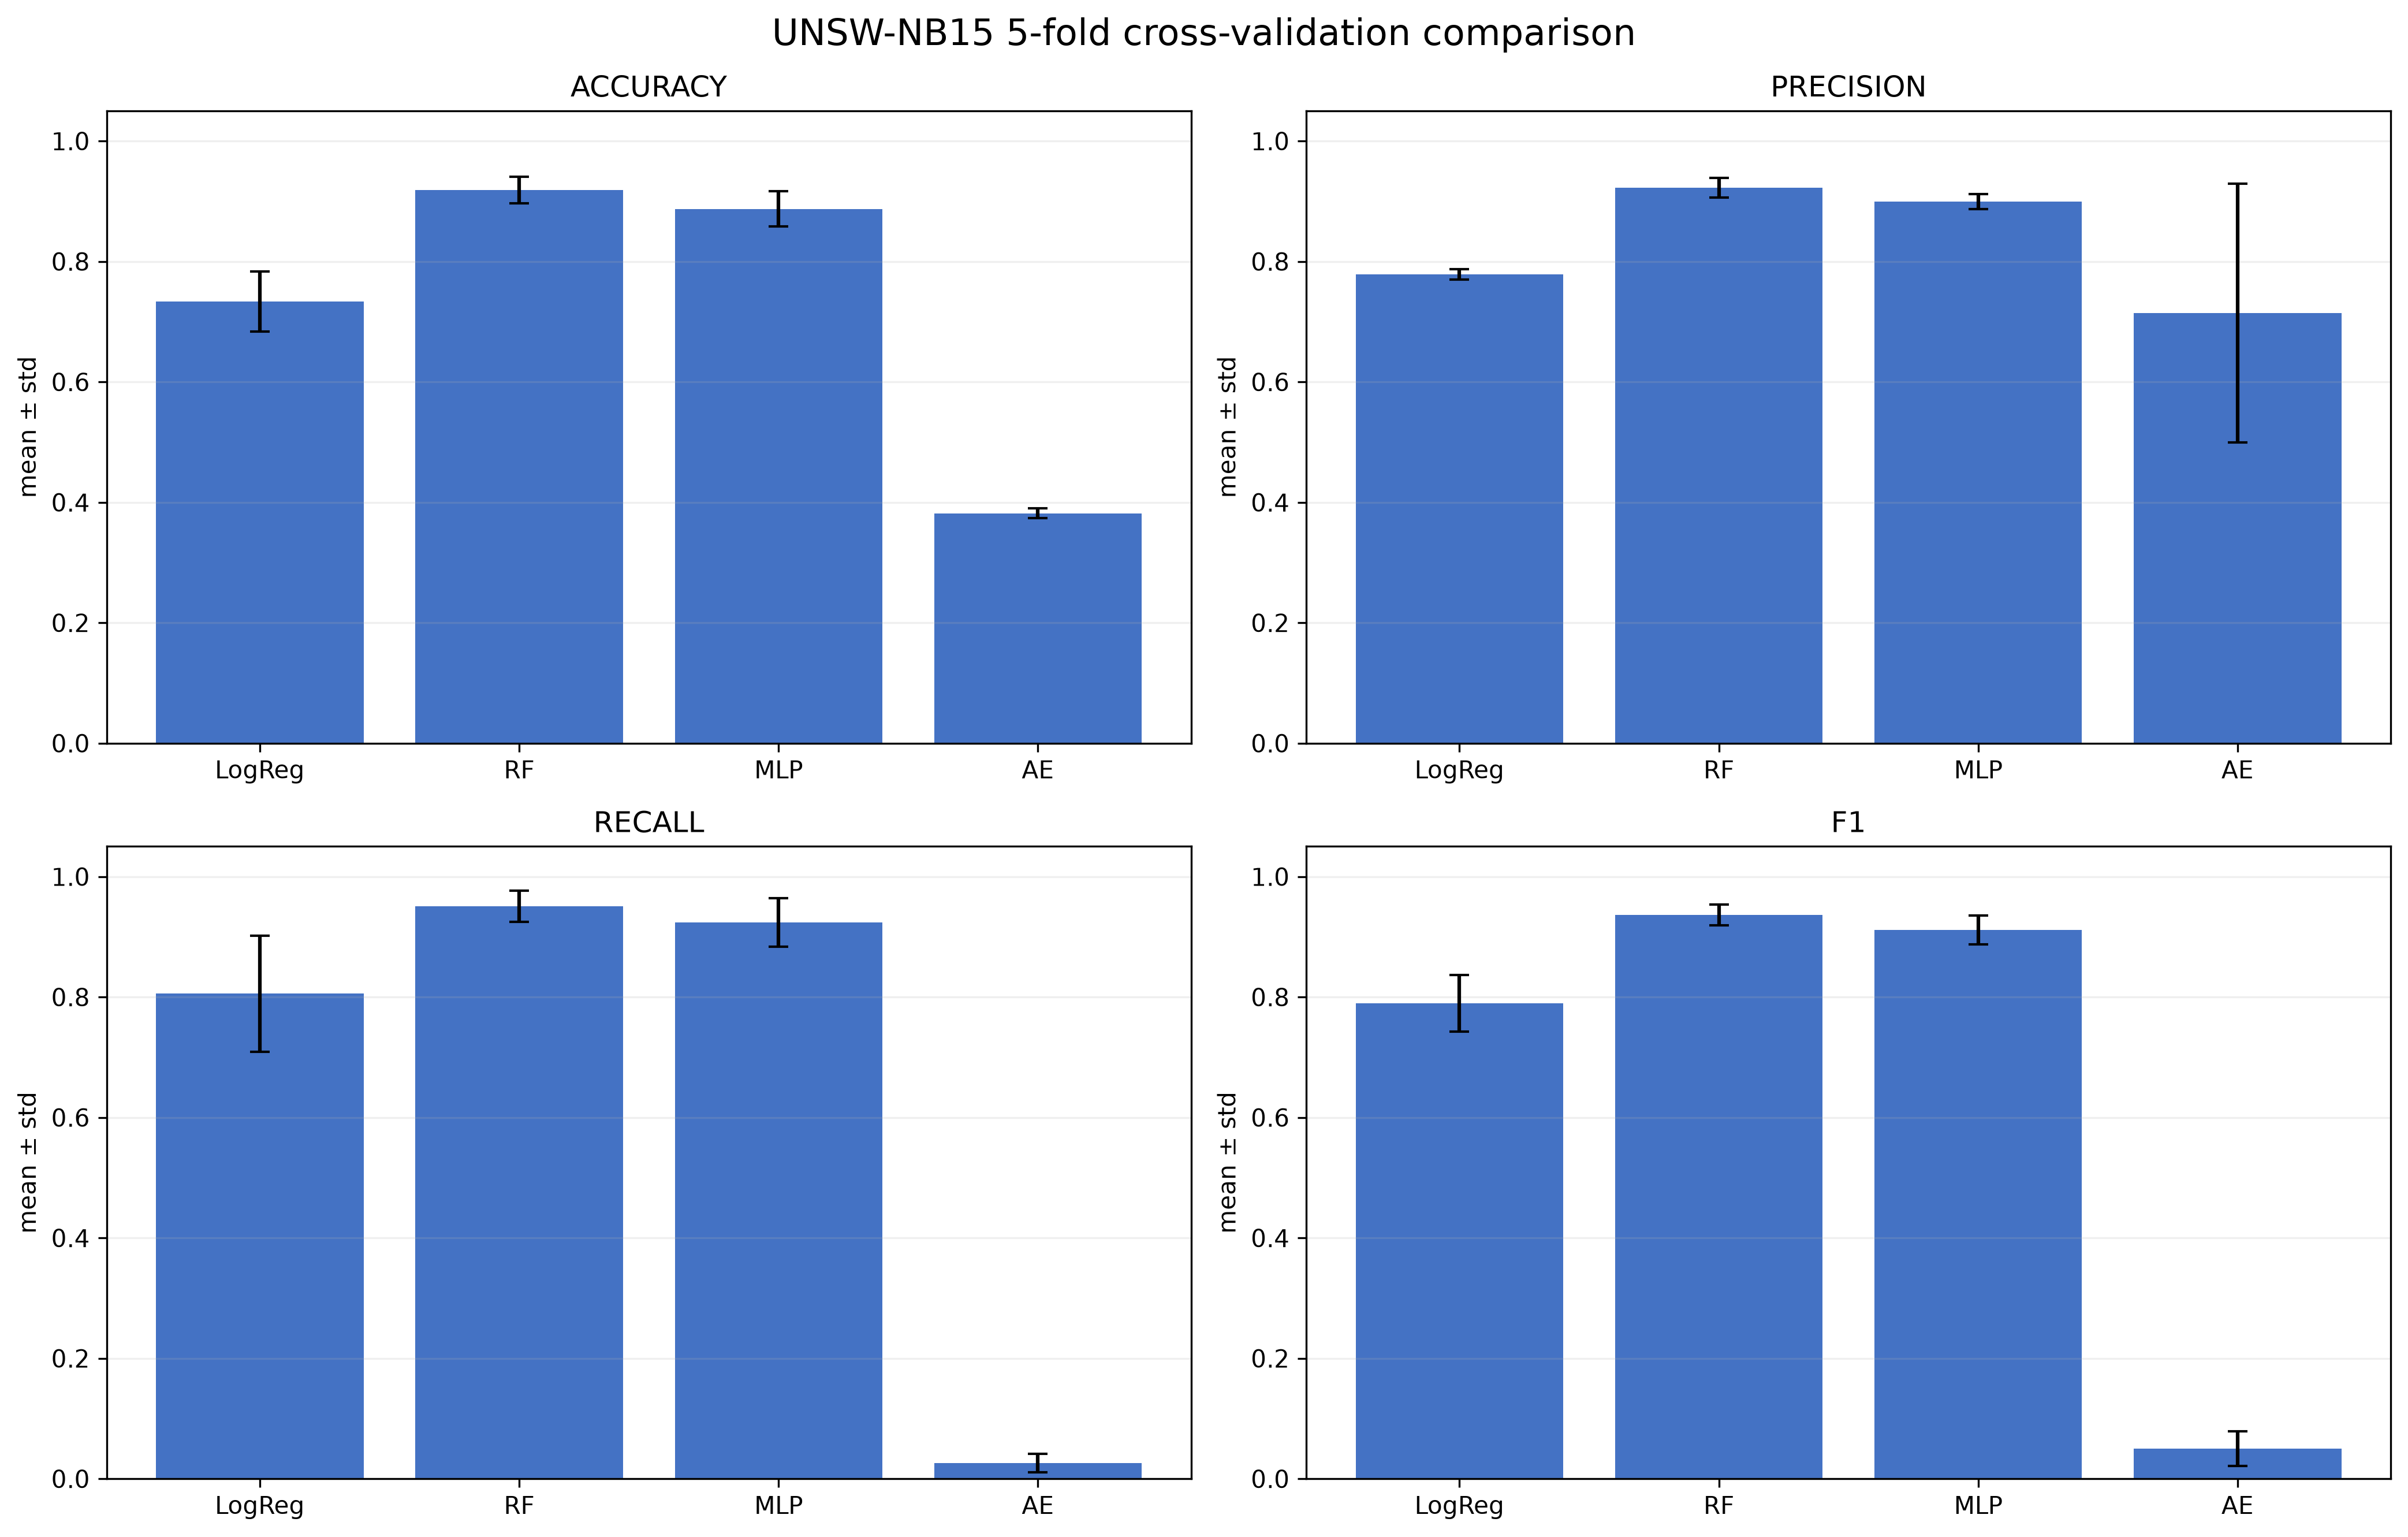

artifacts\experiments\unsw_v03_research_completeness_actual\figures\evaluation\model_comparison_accuracy_precision_recall_f1.png


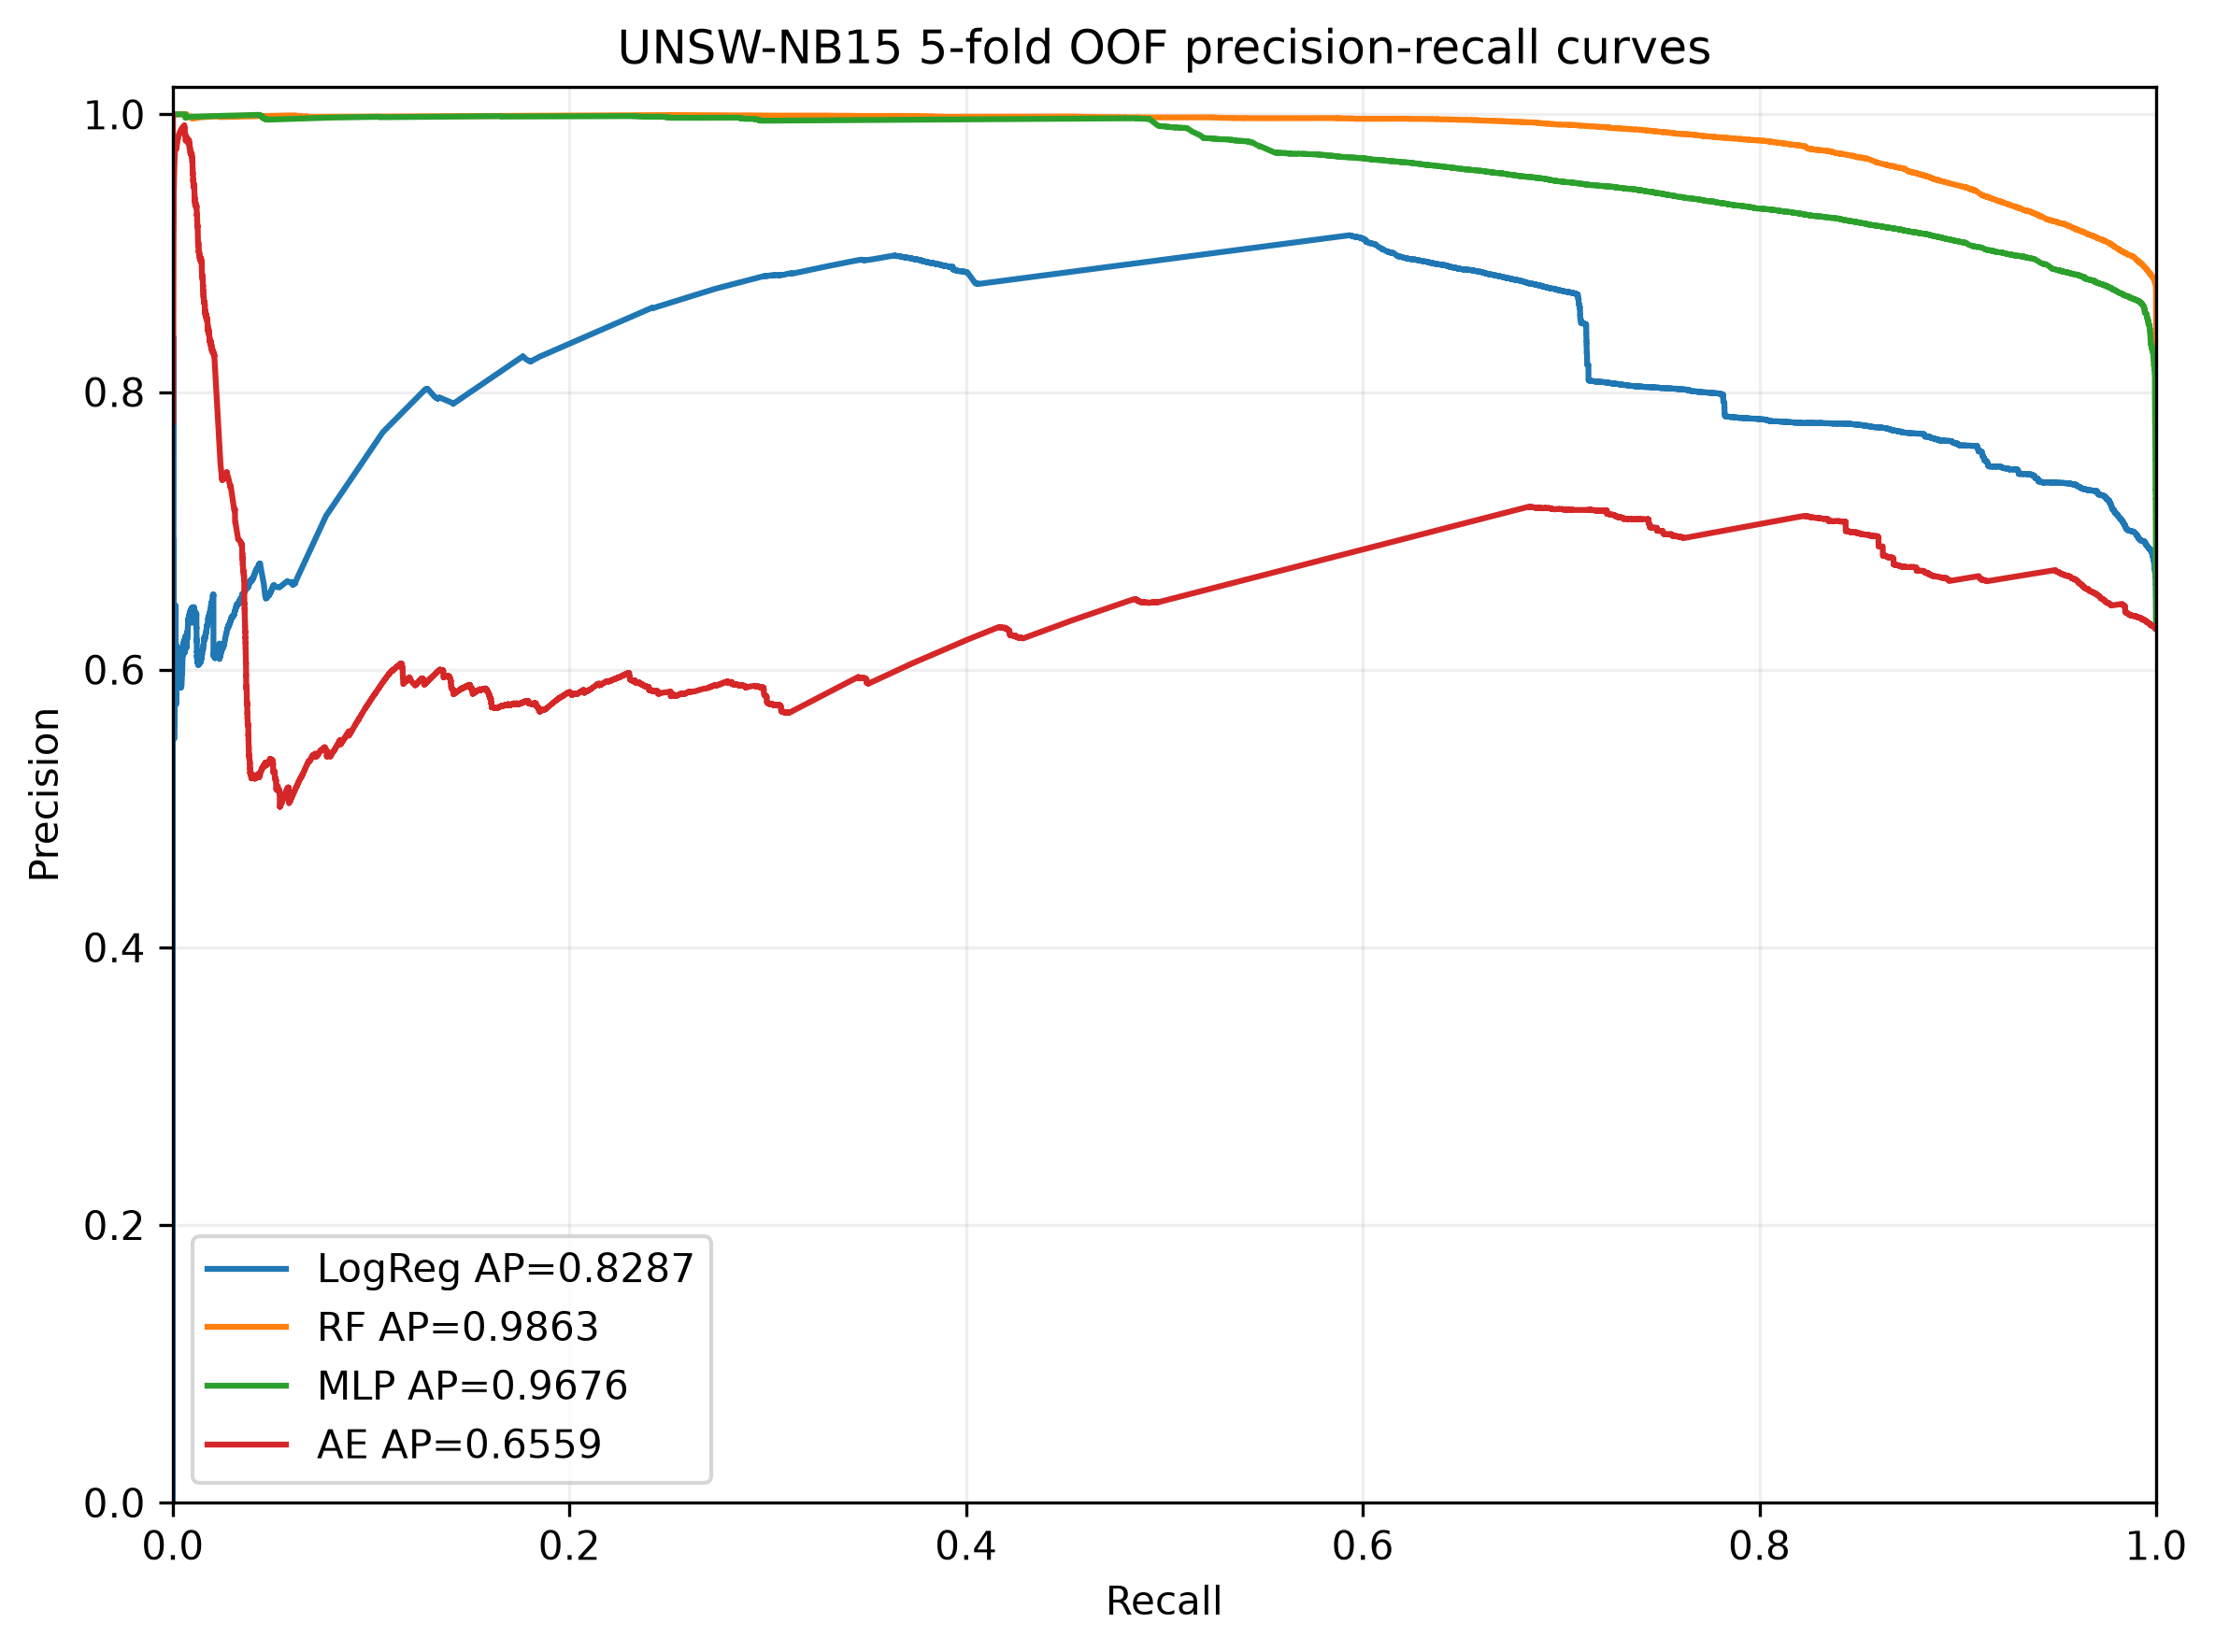

artifacts\experiments\unsw_v03_research_completeness_actual\figures\evaluation\pr_curves_oof.png


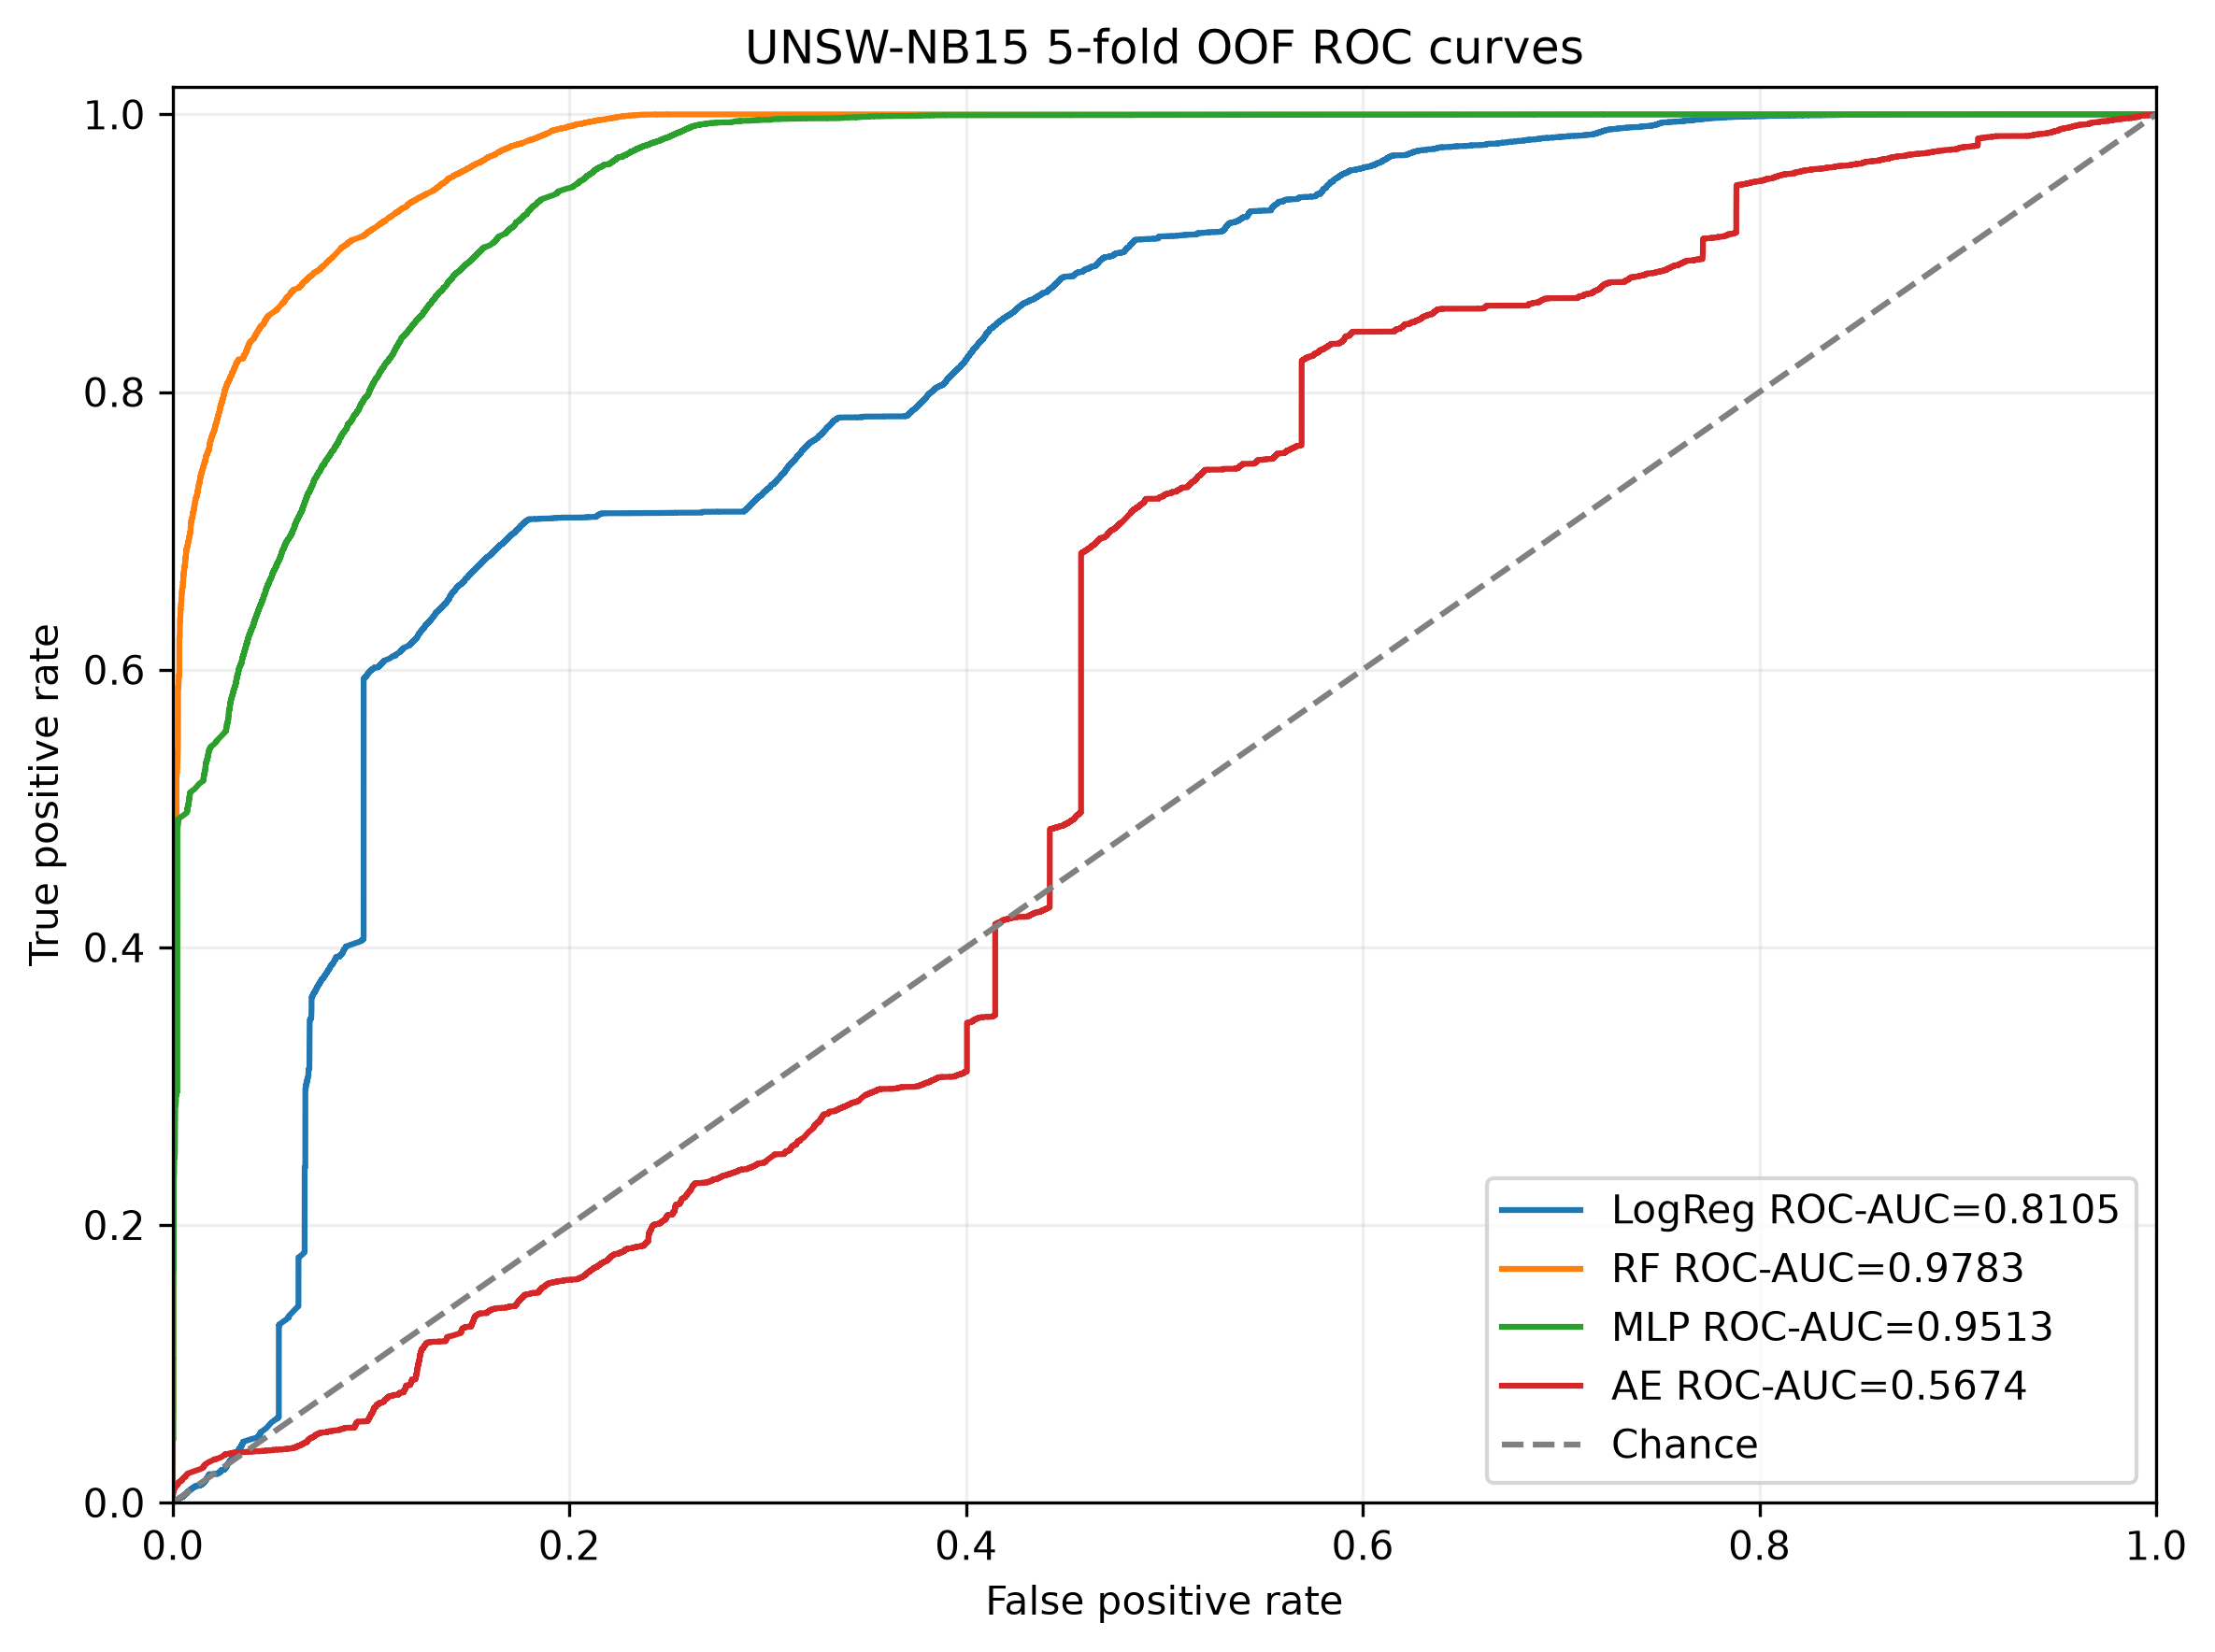

artifacts\experiments\unsw_v03_research_completeness_actual\figures\evaluation\roc_curves_oof.png


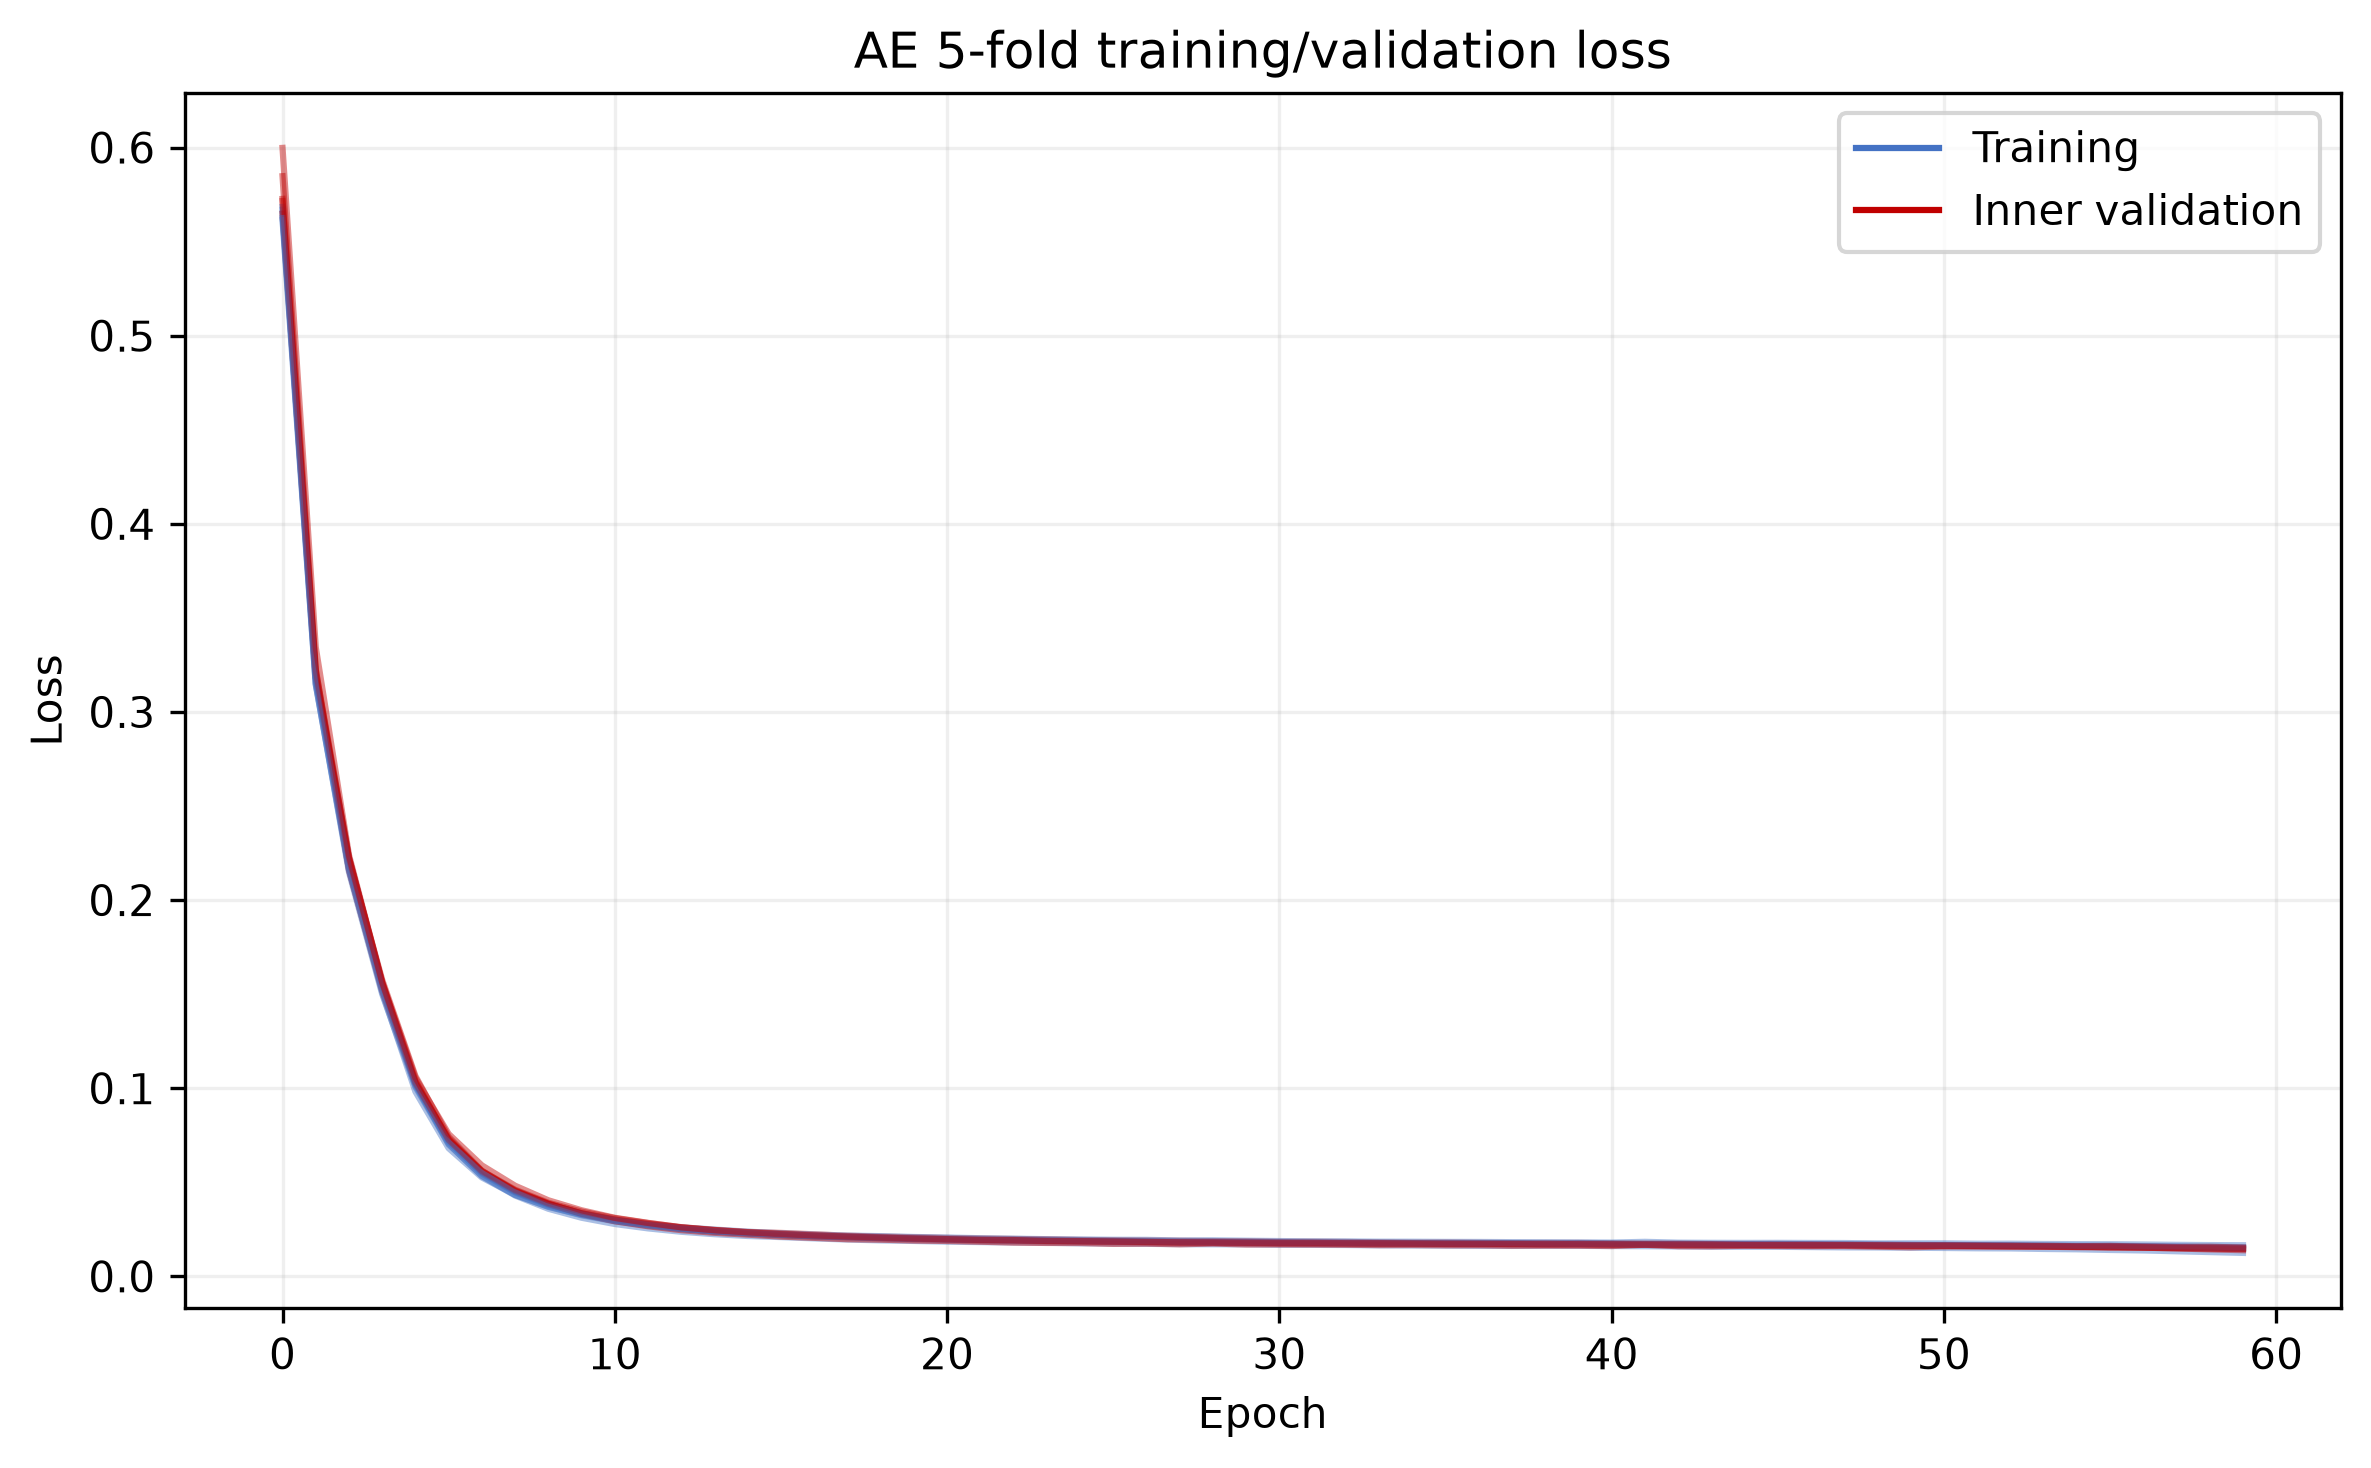

artifacts\experiments\unsw_v03_research_completeness_actual\figures\evaluation\training_history_ae.png


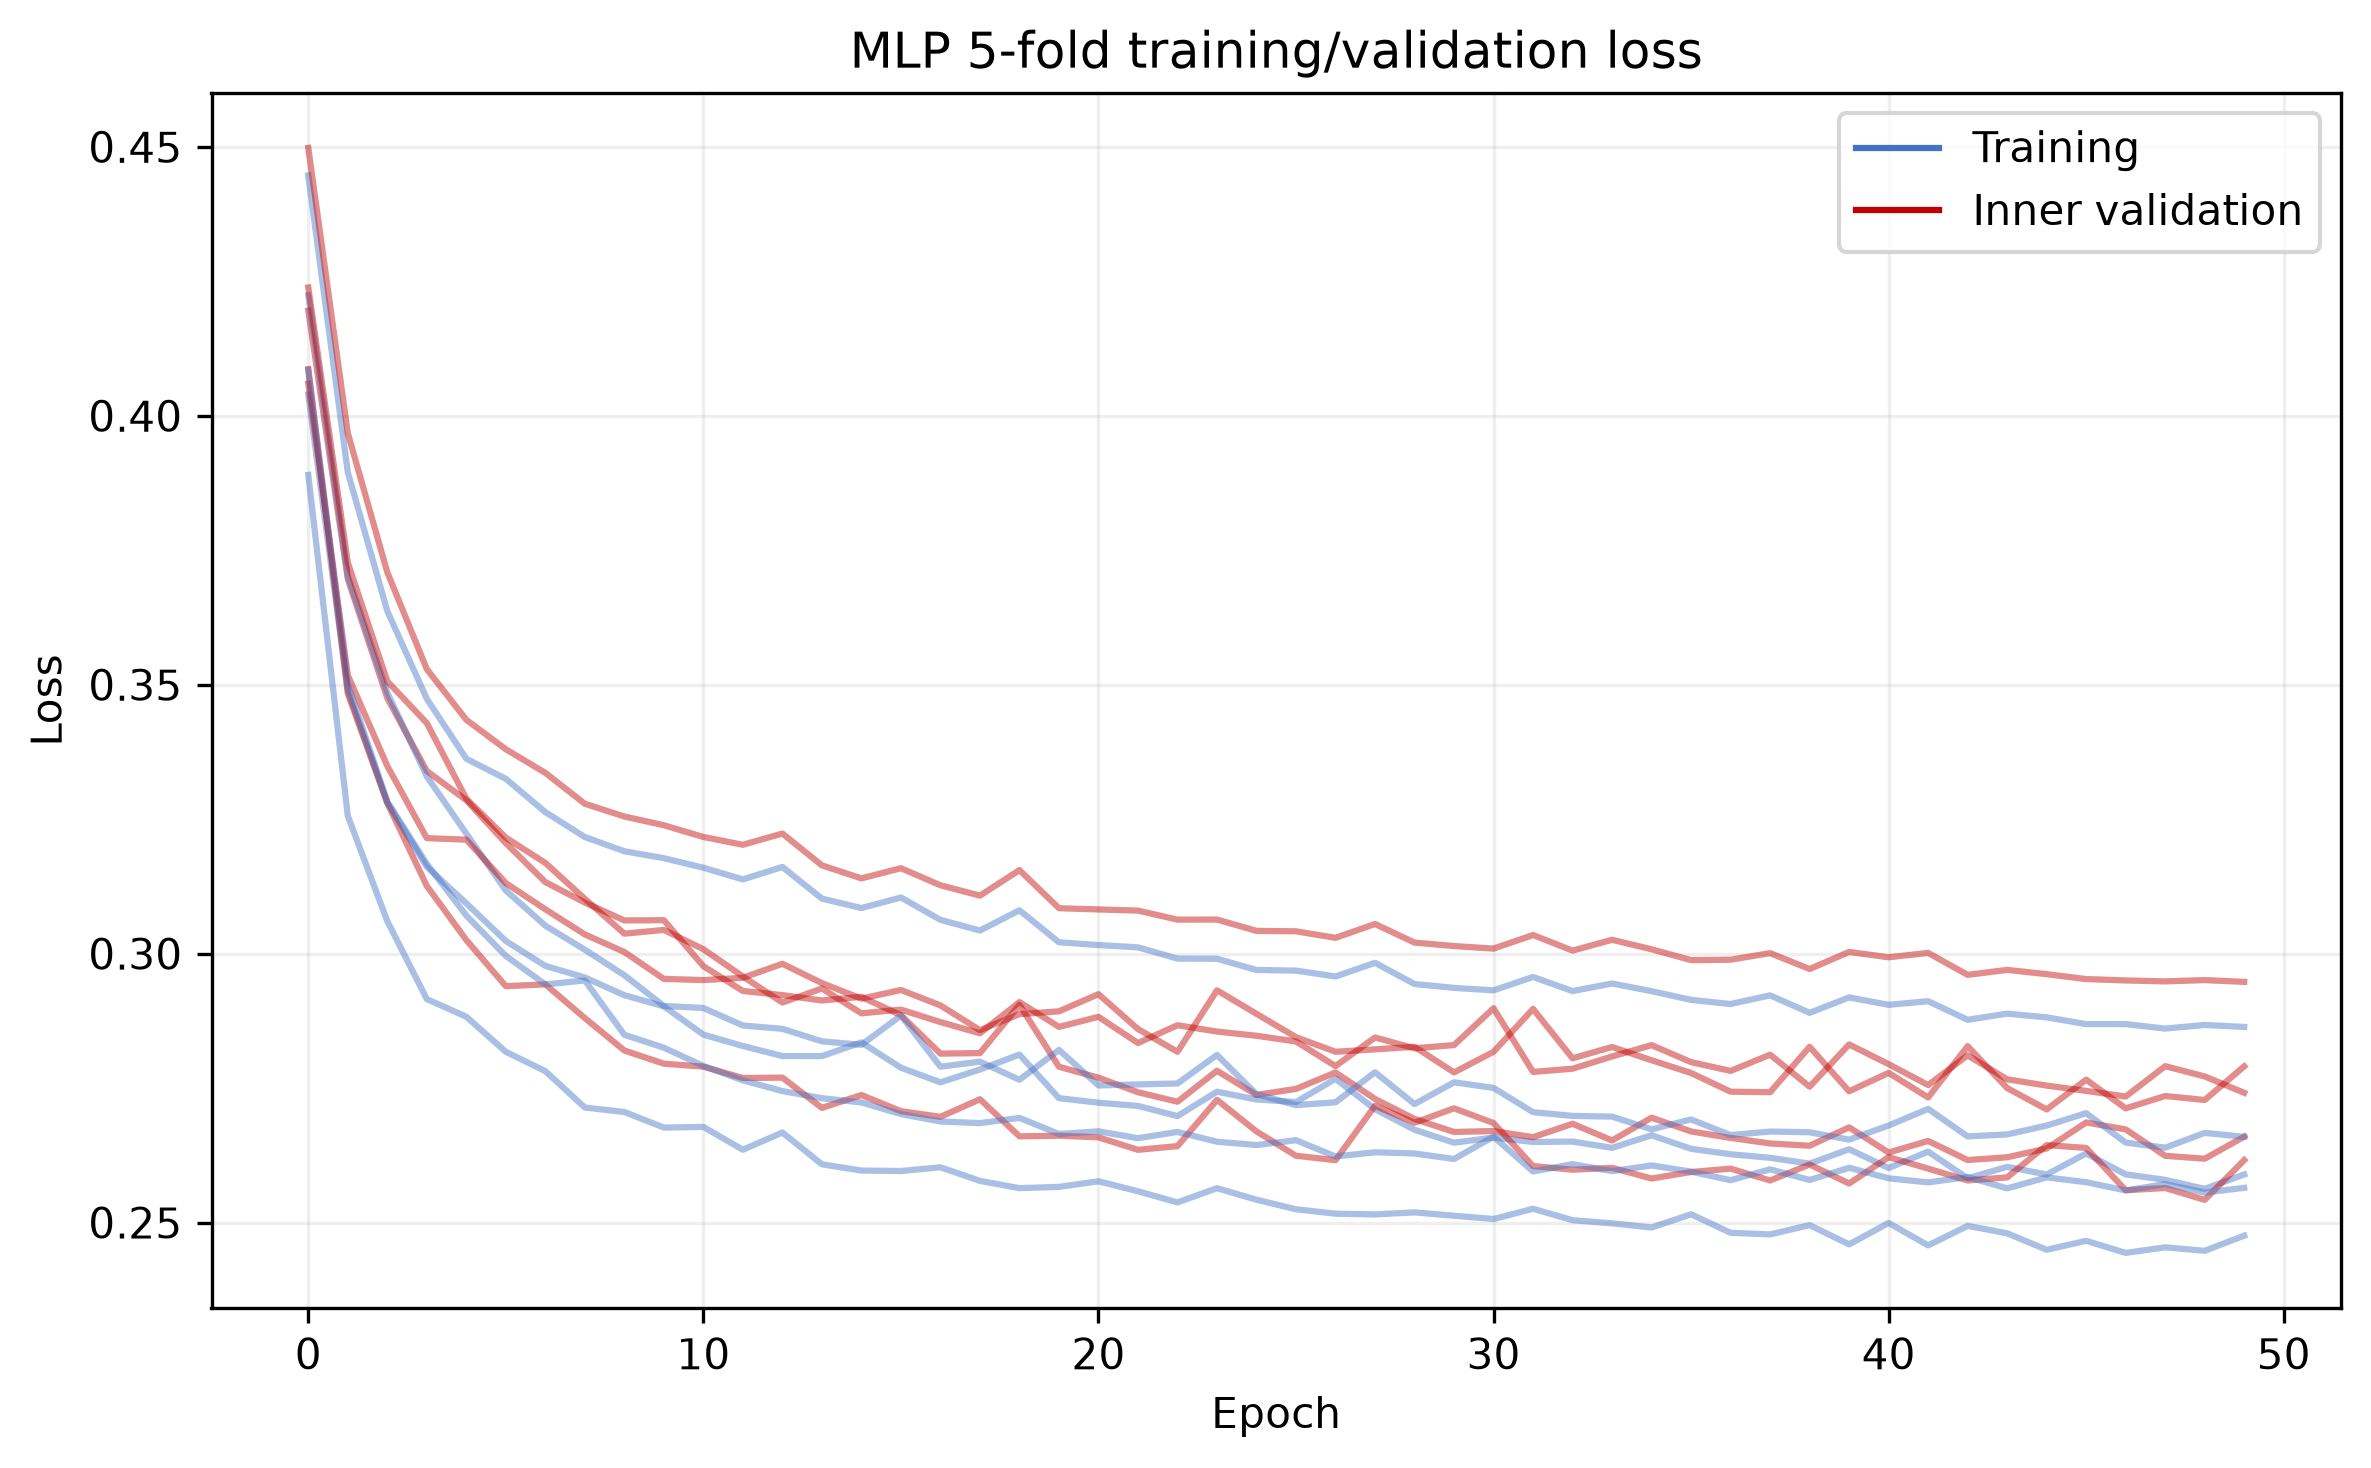

artifacts\experiments\unsw_v03_research_completeness_actual\figures\evaluation\training_history_mlp.png


In [3]:
for path in sorted((output / 'figures' / 'evaluation').glob('*.png')):
    display(Image(filename=str(path), width=900))
    print(path.relative_to(root))

In [4]:
history = json.loads((output / 'training_history.json').read_text(encoding='utf-8'))
for family, records in history.items():
    print(family, 'fold histories:', len(records), 'best epochs:', [record['best_epoch'] for record in records])
print('Checkpoint hashes are recorded in manifest.json; checkpoint files are intentionally not staged for commit.')

LogReg fold histories: 0 best epochs: []
RF fold histories: 0 best epochs: []
MLP fold histories: 5 best epochs: [50, 43, 49, 45, 47]
AE fold histories: 5 best epochs: [60, 60, 60, 60, 60]
Checkpoint hashes are recorded in manifest.json; checkpoint files are intentionally not staged for commit.
